# Notebook 02 — Data Cleaning, Normalization & Preprocessing
**Project:** Predicting Employee Attrition at PeopleFirst Global Services
**Step:** Month 1–2, Weeks 3–5 — Cleaning, Normalization & Preprocessing

---
### Objectives of this notebook
1. Drop ID and legacy columns (no analytical value)
2. Fix `employment_type` casing inconsistency
3. Impute missing values (`manager_rating`, `engagement_score`)
4. Normalize / scale numeric features
5. Encode categorical features
6. Save the cleaned dataset to `data/processed/` for use in NB03+


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
import warnings, os

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

os.makedirs('../data/processed', exist_ok=True)
os.makedirs('../reports', exist_ok=True)

print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load Raw Dataset

In [2]:
DATA_PATH = '../data/raw/PeopleFirst_Workforce_Intelligence.csv'
df = pd.read_csv(DATA_PATH)

print(f"Raw dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)


Raw dataset loaded: 50,500 rows x 36 columns


,employee_id,age,gender,marital_status,education_level,department,job_role,years_at_company,years_in_current_role,promotion_last_5y,...,manager_relationship_score,work_life_balance_score,engagement_score,recruitment_source,employment_type,legacy_hr_record,employee_cluster_id,survey_batch_id,payroll_reference_number,attrition_flag
0,100000,59,Female,Single,Diploma,Sales,Analyst,16,9,0,...,9.193530,7.646637,7.363357,Campus,Intern,880246,59,7571,868037,1
1,100001,49,Male,Single,PhD,HR,Manager,17,5,0,...,6.690203,7.778092,NaN,Referral,Intern,487936,61,5161,579256,0
2,100002,35,Female,Single,Bachelors,Operations,Administrator,9,9,0,...,2.668998,8.827286,1.396038,Job Portal,Permanent,262254,26,8009,172606,1


## 3. Drop ID and Legacy Columns
These 5 columns carry no analytical signal — they are administrative references
and legacy system artefacts that would only add noise to any model.


In [3]:
ID_COLS = [
    'employee_id',
    'legacy_hr_record',
    'employee_cluster_id',
    'survey_batch_id',
    'payroll_reference_number'
]

df.drop(columns=ID_COLS, inplace=True)

print(f"Dropped {len(ID_COLS)} ID/legacy columns.")
print(f"Remaining shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Columns dropped: {ID_COLS}")


Dropped 5 ID/legacy columns.
Remaining shape: 50,500 rows x 31 columns
Columns dropped: ['employee_id', 'legacy_hr_record', 'employee_cluster_id', 'survey_batch_id', 'payroll_reference_number']


## 4. Fix `employment_type` Casing Inconsistency
`Permanent`, `permanent`, and `PERMANENT` are the same category.
We standardize everything to **Title Case** so the model treats them as one.


In [4]:
print("Before fix:")
print(df['employment_type'].value_counts())

df['employment_type'] = df['employment_type'].str.strip().str.title()

print("\nAfter fix:")
print(df['employment_type'].value_counts())
print("\n>> All variants now unified to 'Permanent'")


Before fix:
employment_type
Permanent    16867
Contract     16204
Intern       16110
permanent      675
PERMANENT      644
Name: count, dtype: int64

After fix:
employment_type
Permanent    18186
Contract     16204
Intern       16110
Name: count, dtype: int64

>> All variants now unified to 'Permanent'


## 5. Handle Missing Values
Two columns have ~10% missing each:
- `manager_rating` — likely missing when the employee had no formal manager review
- `engagement_score` — likely non-response in the engagement survey

**Strategy: Median imputation grouped by `department`**
Using the group median (by department) is more accurate than the global median,
since engagement and manager ratings naturally vary across departments.


In [5]:
print("Missing values BEFORE imputation:")
print(df[['manager_rating', 'engagement_score']].isnull().sum())

# Median imputation grouped by department
for col in ['manager_rating', 'engagement_score']:
    df[col] = df.groupby('department')[col].transform(
        lambda x: x.fillna(x.median())
    )

# If any still missing (small dept with all nulls), fill with global median
df['manager_rating'] = df['manager_rating'].fillna(df['manager_rating'].median())
df['engagement_score'] = df['engagement_score'].fillna(df['engagement_score'].median())

print("\nMissing values AFTER imputation:")
print(df[['manager_rating', 'engagement_score']].isnull().sum())
print("\n>> No missing values remaining.")


Missing values BEFORE imputation:
manager_rating      5033
engagement_score    5029
dtype: int64

Missing values AFTER imputation:
manager_rating      0
engagement_score    0
dtype: int64

>> No missing values remaining.


In [6]:
total_missing = df.isnull().sum().sum()
print(f"Total missing values across entire dataset: {total_missing}")
print("Dataset is clean." if total_missing == 0 else "WARNING: Still has missing values!")


Total missing values across entire dataset: 0
Dataset is clean.


## 6. Encode Categorical Features
Machine learning models only understand numbers — we need to convert all
text categories into numeric representations.

**Strategy used:**
- **Ordinal columns** (with a natural order) -> mapped manually to integers
- **Nominal columns** (no natural order) -> Label Encoding (for tree-based models like LightGBM/XGBoost which handle this well)

> Note: For Logistic Regression we would typically use One-Hot Encoding,
> but since our primary model is LightGBM, Label Encoding is appropriate.
> We will note this distinction in the model notebook.


In [7]:
# Ordinal mappings (meaningful order)

# education_level
education_map = {'Diploma': 1, 'Bachelors': 2, 'Masters': 3, 'PhD': 4}
df['education_level'] = df['education_level'].map(education_map)
print("education_level mapped:", education_map)

# business_travel_frequency
travel_map = {'Rare': 1, 'Occasional': 2, 'Frequent': 3}
df['business_travel_frequency'] = df['business_travel_frequency'].map(travel_map)
print("business_travel_frequency mapped:", travel_map)

# promotion_last_5y is already 0/1 binary - no change needed
print("promotion_last_5y: already binary (0/1)")


education_level mapped: {'Diploma': 1, 'Bachelors': 2, 'Masters': 3, 'PhD': 4}
business_travel_frequency mapped: {'Rare': 1, 'Occasional': 2, 'Frequent': 3}
promotion_last_5y: already binary (0/1)


In [8]:
# Nominal encoding (Label Encoding)

nominal_cols = [
    'gender', 'marital_status', 'department',
    'job_role', 'employment_type', 'recruitment_source'
]

le = LabelEncoder()
encoding_map = {}

for col in nominal_cols:
    df[col] = le.fit_transform(df[col].astype(str))
    encoding_map[col] = dict(zip(le.classes_, le.transform(le.classes_).tolist()))
    print(f"{col}: {encoding_map[col]}")

print("\nAll categorical columns encoded successfully.")


gender: {'Female': 0, 'Male': 1}
marital_status: {'Divorced': 0, 'Married': 1, 'Single': 2}
department: {'Customer Support': 0, 'Finance': 1, 'HR': 2, 'Marketing': 3, 'Operations': 4, 'Sales': 5, 'Technology': 6}
job_role: {'Administrator': 0, 'Analyst': 1, 'Consultant': 2, 'Director': 3, 'Engineer': 4, 'Manager': 5}
employment_type: {'Contract': 0, 'Intern': 1, 'Permanent': 2}
recruitment_source: {'Agency': 0, 'Campus': 1, 'Internal': 2, 'Job Portal': 3, 'Referral': 4}

All categorical columns encoded successfully.


In [9]:
print("Column dtypes after encoding:")
print(df.dtypes)
print(f"\nAny remaining object columns: {df.select_dtypes(include='object').columns.tolist()}")


Column dtypes after encoding:
age                                int64
gender                             int64
marital_status                     int64
education_level                    int64
department                         int64
job_role                           int64
years_at_company                   int64
years_in_current_role              int64
promotion_last_5y                  int64
monthly_salary                   float64
annual_bonus                     float64
salary_hike_pct                  float64
performance_rating               float64
manager_rating                   float64
goal_achievement_pct             float64
avg_monthly_overtime_hours       float64
avg_weekly_work_hours            float64
remote_work_days_per_month         int64
business_travel_frequency          int64
absenteeism_days_last_12m          int64
late_arrivals_last_12m             int64
training_hours_last_12m          float64
certifications_completed           int64
learning_platform_usage_hou

## 7. Normalize Numeric Features
Features come from multiple source systems with very different scales:
- `monthly_salary`: 15,000 to 1,000,000
- `engagement_score`: 1 to 10
- `age`: 21 to 59

Without normalization, high-magnitude features (like salary) can dominate
distance calculations and gradient updates in the model.

**Strategy: StandardScaler (Z-score normalization)**
Transforms each feature to have mean = 0 and std = 1.
Applied only to continuous numeric columns — binary and ordinal columns are left as-is.

> The scaler is fit on training data ONLY to avoid data leakage.
> Here we scale the full cleaned dataset and will re-apply properly in NB05.


In [10]:
# Columns to scale — continuous numerics only
# Exclude: binary columns, ordinal-encoded columns, and the target
SCALE_COLS = [
    'age',
    'monthly_salary', 'annual_bonus', 'salary_hike_pct',
    'performance_rating', 'manager_rating', 'goal_achievement_pct',
    'avg_monthly_overtime_hours', 'avg_weekly_work_hours',
    'remote_work_days_per_month',
    'absenteeism_days_last_12m', 'late_arrivals_last_12m',
    'training_hours_last_12m', 'certifications_completed',
    'learning_platform_usage_hours',
    'employee_satisfaction_score', 'manager_relationship_score',
    'work_life_balance_score', 'engagement_score',
    'years_at_company', 'years_in_current_role'
]

scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[SCALE_COLS] = scaler.fit_transform(df[SCALE_COLS])

print(f"Scaled {len(SCALE_COLS)} numeric columns.")
print("\nSample - monthly_salary before vs after scaling:")
print(f"  Before -> min: {df['monthly_salary'].min():,.0f}  max: {df['monthly_salary'].max():,.0f}  mean: {df['monthly_salary'].mean():,.0f}")
print(f"  After  -> min: {df_scaled['monthly_salary'].min():.3f}  max: {df_scaled['monthly_salary'].max():.3f}  mean: {df_scaled['monthly_salary'].mean():.3f}")


Scaled 21 numeric columns.

Sample - monthly_salary before vs after scaling:
  Before -> min: 15,000  max: 1,000,000  mean: 76,980
  After  -> min: -1.292  max: 19.235  mean: -0.000


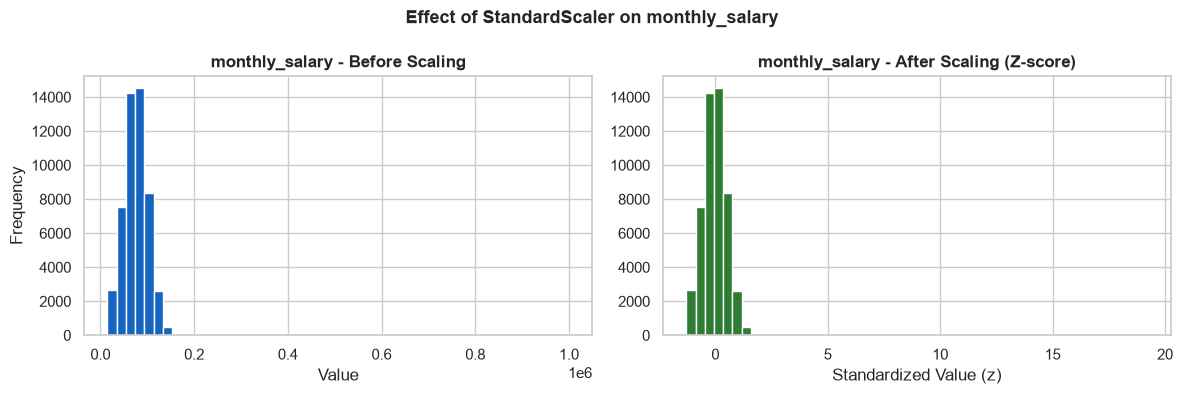

Chart saved to reports/


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['monthly_salary'], bins=50, color='#1565C0', edgecolor='white')
axes[0].set_title('monthly_salary - Before Scaling', fontweight='bold')
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Frequency')

axes[1].hist(df_scaled['monthly_salary'], bins=50, color='#2E7D32', edgecolor='white')
axes[1].set_title('monthly_salary - After Scaling (Z-score)', fontweight='bold')
axes[1].set_xlabel('Standardized Value (z)')

plt.suptitle('Effect of StandardScaler on monthly_salary', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/02_salary_scaling.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved to reports/")


## 8. Final Dataset Check

In [12]:
print("=== Final Cleaned Dataset ===")
print(f"Shape       : {df_scaled.shape[0]:,} rows x {df_scaled.shape[1]} columns")
print(f"Missing vals: {df_scaled.isnull().sum().sum()}")
print(f"\nTarget distribution:")
print(df_scaled['attrition_flag'].value_counts())
print()
df_scaled.head()


=== Final Cleaned Dataset ===
Shape       : 50,500 rows x 31 columns
Missing vals: 0

Target distribution:
attrition_flag
1    31029
0    19471
Name: count, dtype: int64



,age,gender,marital_status,education_level,department,job_role,years_at_company,years_in_current_role,promotion_last_5y,monthly_salary,...,training_hours_last_12m,certifications_completed,learning_platform_usage_hours,employee_satisfaction_score,manager_relationship_score,work_life_balance_score,engagement_score,recruitment_source,employment_type,attrition_flag
0,1.691996,0,2,1,5,1,1.131424,1.568073,0,0.317586,...,1.197289,0.712801,1.715785,-0.021381,1.422728,0.830032,0.762247,1,1,1
1,0.800890,1,2,4,2,5,1.304840,0.178431,0,-0.199512,...,0.193722,0.002307,2.007204,-0.800149,0.461273,0.880659,-0.011468,4,1,0
2,-0.446660,0,2,2,4,0,-0.082488,1.568073,0,1.427577,...,1.935969,0.002307,-0.207250,1.207685,-1.083156,1.284740,-1.670497,3,2,1
3,-1.070434,1,0,3,2,5,-0.602735,1.220662,0,-0.665985,...,-0.376595,0.002307,-0.979800,-0.906269,0.089345,-1.396689,-0.730810,0,0,1
4,0.088004,0,2,4,6,3,0.090928,0.873252,0,-0.104222,...,-0.184145,0.002307,1.196704,-0.379663,0.068071,0.920068,0.400885,1,1,1


In [13]:
# Confirm all columns are numeric now
non_numeric = df_scaled.select_dtypes(exclude='number').columns.tolist()
if non_numeric:
    print(f"WARNING - non-numeric columns still present: {non_numeric}")
else:
    print("All columns are numeric. Ready for ML.")


All columns are numeric. Ready for ML.


## 9. Feature Correlation with Attrition

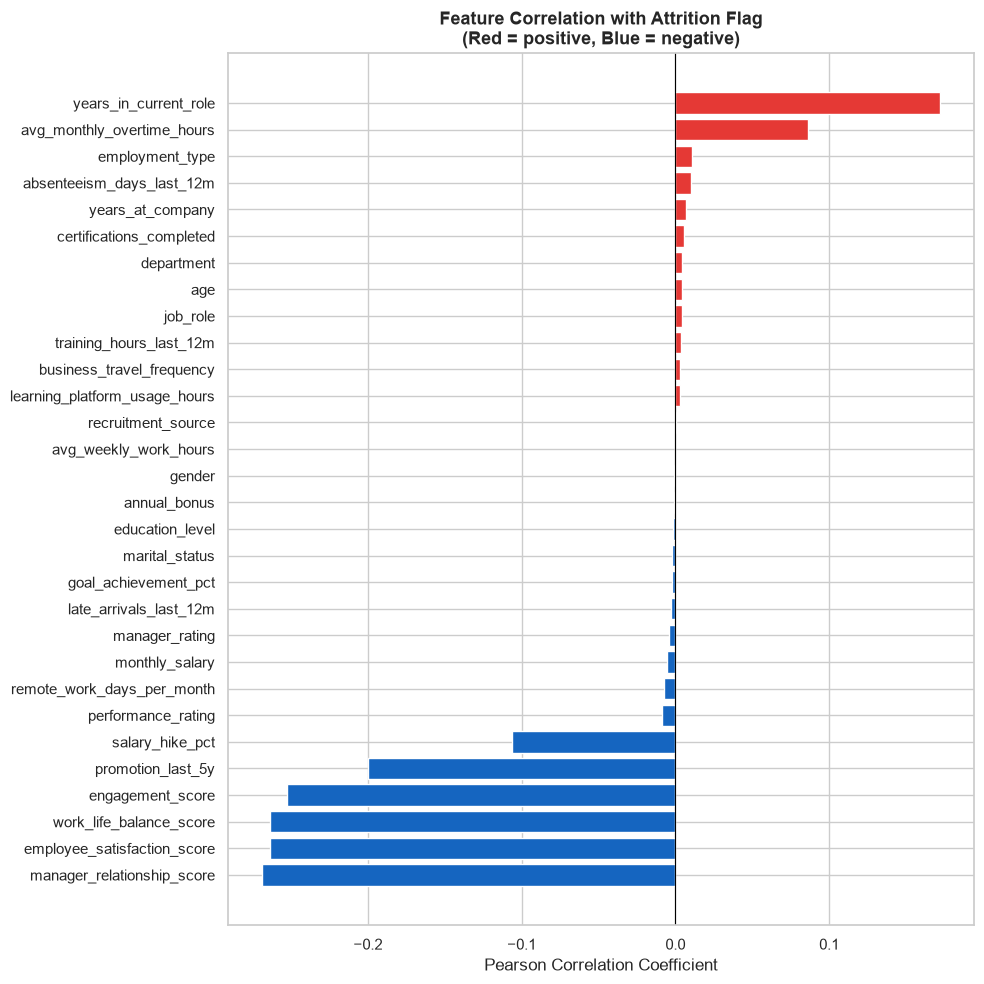


Top 5 positively correlated with attrition:
years_at_company              0.007
absenteeism_days_last_12m     0.010
employment_type               0.010
avg_monthly_overtime_hours    0.086
years_in_current_role         0.172
Name: attrition_flag, dtype: float64

Top 5 negatively correlated with attrition:
manager_relationship_score    -0.269
employee_satisfaction_score   -0.264
work_life_balance_score       -0.264
engagement_score              -0.253
promotion_last_5y             -0.200
Name: attrition_flag, dtype: float64


In [14]:
# Correlation of all features with target
target_corr = df_scaled.corr()['attrition_flag'].drop('attrition_flag').sort_values()

fig, ax = plt.subplots(figsize=(10, 10))
colors = ['#E53935' if v > 0 else '#1565C0' for v in target_corr.values]
ax.barh(target_corr.index, target_corr.values, color=colors, edgecolor='white')
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_title('Feature Correlation with Attrition Flag\n(Red = positive, Blue = negative)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Pearson Correlation Coefficient')
plt.tight_layout()
plt.savefig('../reports/02_feature_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nTop 5 positively correlated with attrition:")
print(target_corr.tail(5).round(3))
print("\nTop 5 negatively correlated with attrition:")
print(target_corr.head(5).round(3))


## 10. Save Cleaned Dataset

In [15]:
OUTPUT_PATH = '../data/processed/PeopleFirst_cleaned.csv'
df_scaled.to_csv(OUTPUT_PATH, index=False)

print(f"Cleaned dataset saved to: {OUTPUT_PATH}")
print(f"Shape: {df_scaled.shape[0]:,} rows x {df_scaled.shape[1]} columns")
print()
print("=== Notebook 02 Complete ===")
print("Proceed to: notebooks/03_eda.ipynb")


Cleaned dataset saved to: ../data/processed/PeopleFirst_cleaned.csv
Shape: 50,500 rows x 31 columns

=== Notebook 02 Complete ===
Proceed to: notebooks/03_eda.ipynb
